In [92]:
from common.read_dataset.mm_dataset import read_mm_dataset

In [93]:
df = read_mm_dataset("../data/many-models-bap/res.json")
df = df.drop(columns=["patient_temperature", "evaluation_results"])
df["text"] = df["conversation"].apply(
    lambda conv: "\n".join(
        [
            msg["content"] for msg in conv 
            if msg["name"] == "Counselor"
        ]
    )
)
df

,conversation,simulation_id,model,counselor_temperature,text
0,"[{'role': 'assistant', 'name': 'Patient', 'con...",qwen2.5-32b_20241120144152_t0.1_n1,qwen2.5:32b,0.1,"Ciao, sono Demetra, tua consulente per la salu..."
1,"[{'role': 'assistant', 'name': 'Patient', 'con...",qwen2.5-32b_20241120144152_t0.1_n3,qwen2.5:32b,0.1,"Ciao, mi chiamo Demetra e sono un chatbot espe..."
2,"[{'role': 'assistant', 'name': 'Patient', 'con...",qwen2.5-32b_20241120144152_t0.1_n2,qwen2.5:32b,0.1,"Ciao, sono Demetra, tua consulente per la salu..."
3,"[{'role': 'assistant', 'name': 'Patient', 'con...",qwen2.5-32b_20241120144152_t0.1_n5,qwen2.5:32b,0.1,"Ciao, sono Demetra, tua consulente per la salu..."
4,"[{'role': 'assistant', 'name': 'Patient', 'con...",qwen2.5-32b_20241120144152_t0.1_n6,qwen2.5:32b,0.1,"Ciao, sono Demetra, tua consulente per la salu..."
...,...,...,...,...,...
995,"[{'role': 'assistant', 'name': 'Patient', 'con...",aya-expanse-32b_20241121094815_t0.9_n47,aya-expanse:32b,0.9,"Ciao, sono Demetra, un assistente di coaching ..."
996,"[{'role': 'assistant', 'name': 'Patient', 'con...",aya-expanse-32b_20241121094815_t0.9_n46,aya-expanse:32b,0.9,"Ciao, sono Demetra, un chatbot esperto in coac..."
997,"[{'role': 'assistant', 'name': 'Patient', 'con...",aya-expanse-32b_20241121094815_t0.9_n48,aya-expanse:32b,0.9,"Ciao, sono Demetra, un chatbot esperto in coac..."
998,"[{'role': 'assistant', 'name': 'Patient', 'con...",aya-expanse-32b_20241121094815_t0.9_n50,aya-expanse:32b,0.9,"Ciao, sono Demetra, un chatbot esperto in coac..."


In [94]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.cluster import HDBSCAN
from sklearn.cluster import AgglomerativeClustering

In [95]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_df=0.9,
    min_df=0.01,
    preprocessor=lambda text: "".join(
        [c for c in text if not c.isdigit()]
    ),  # remove digits
)

kmeans = KMeans(n_clusters=4, random_state=42)

hdbscan = HDBSCAN(
    # min_cluster_size=15,
    metric="cosine",
    copy=False
)

hierarchical = AgglomerativeClustering(
    n_clusters=4,
    # affinity="cosine",
    linkage="average"
)

In [96]:
X = vectorizer.fit_transform(df["text"])

In [97]:
vectorizer.get_feature_names_out()

array(['Abbiamo', 'Abbiamo anche', 'Abbiamo stabilito', ..., 'zucchero',
       'zucchero aggiunto', 'zucchero nella'], shape=(6899,), dtype=object)

In [98]:
# Fit KMeans
kmeans.fit(X)

df["kmeans_cluster"] = kmeans.labels_

In [99]:
# Fit HDBSCAN
hdbscan.fit(X)

df["hdbscan_cluster"] = hdbscan.labels_

In [100]:
# Fit Hierarchical Clustering
hierarchical.fit(X.toarray())

df["hierarchical_cluster"] = hierarchical.labels_

In [101]:
import seaborn as sns
import matplotlib.pyplot as plt

In [102]:
import umap
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

In [103]:
umap_model = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="cosine",
    random_state=42,
    n_jobs=1,
)

X_umap = umap_model.fit_transform(X)

In [104]:
X_tsne = TSNE(
    n_components=2, learning_rate="auto", init="random", perplexity=10
).fit_transform(X.toarray())

In [105]:
X_pca = PCA(n_components=2, random_state=42).fit_transform(X.toarray())

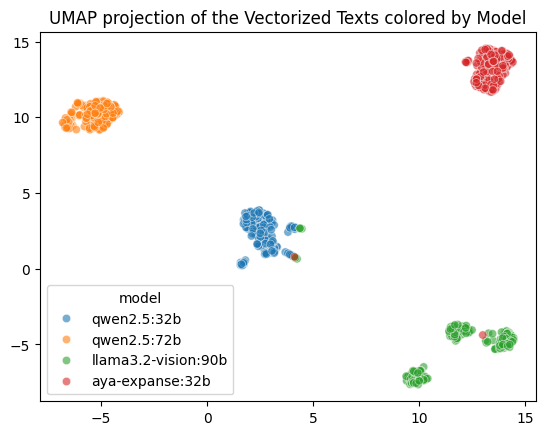

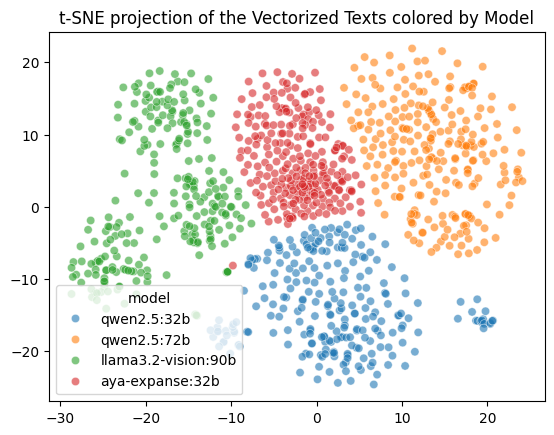

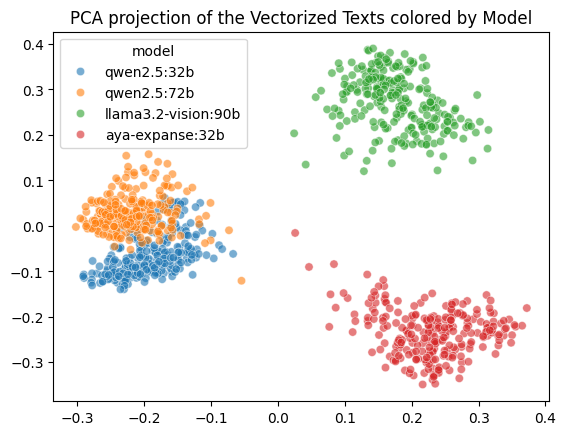

In [106]:
sns.scatterplot(
    x=X_umap[:, 0],
    y=X_umap[:, 1],
    hue=df["model"],
    alpha=0.6,
)
plt.title("UMAP projection of the Vectorized Texts colored by Model")

plt.show()

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=df["model"],
    alpha=0.6,
)
plt.title("t-SNE projection of the Vectorized Texts colored by Model")
plt.show()

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["model"],
    alpha=0.6,
)
plt.title("PCA projection of the Vectorized Texts colored by Model")
plt.show()

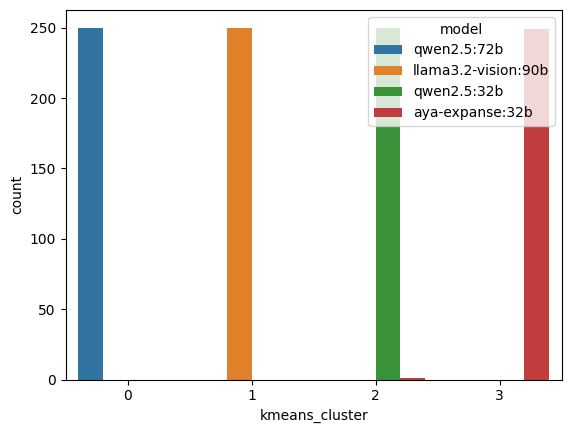

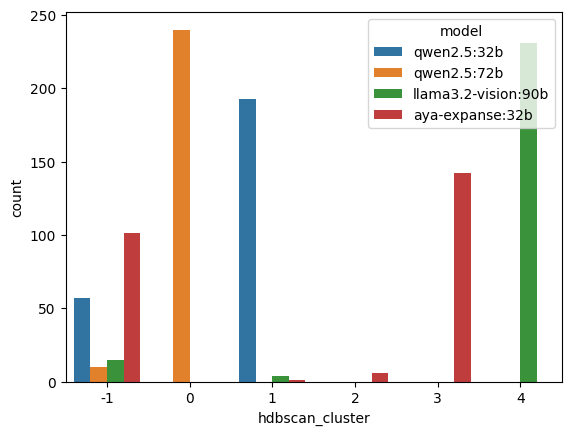

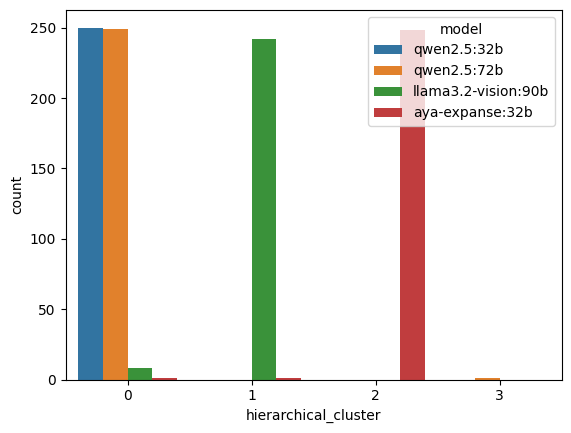

In [107]:
sns.countplot(data=df, x='kmeans_cluster', hue='model')
plt.show()

sns.countplot(data=df, x='hdbscan_cluster', hue='model')
plt.show()

sns.countplot(data=df, x='hierarchical_cluster', hue='model')
plt.show()